Tamaño: (120, 120)
Modo: RGB


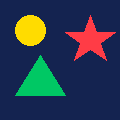

In [6]:
from PIL import Image, ImageDraw

img = Image.new("RGB", (120, 120), color=(20, 35, 80))

draw = ImageDraw.Draw(img)


draw.ellipse((15, 15, 45, 45), fill=(255, 220, 0))

draw.polygon([(15, 95), (40, 55), (65, 95)], fill=(0, 200, 100))

draw.polygon(
    [(90, 15), (96, 32), (115, 32), (100, 43),
     (106, 60), (90, 49), (74, 60), (80, 43),
     (65, 32), (84, 32)],
    fill=(255, 60, 70)
)

print("Tamaño:", img.size)
print("Modo:", img.mode)

img.save("mi_imagen.png")
display(img)

In [7]:

imagen = Image.open("mi_imagen.png")

print("Tamaño:", imagen.size)
print("Modo:", imagen.mode)
print("Formato:", imagen.format)

fondo = (5, 5)
circulo = (30, 30)
triangulo = (40, 80)
estrella = (90, 35)

print("Píxel del fondo:", imagen.getpixel(fondo))
print("Píxel del círculo:", imagen.getpixel(circulo))
print("Píxel del triángulo:", imagen.getpixel(triangulo))
print("Píxel de la estrella:", imagen.getpixel(estrella))

Tamaño: (120, 120)
Modo: RGB
Formato: PNG
Píxel del fondo: (20, 35, 80)
Píxel del círculo: (255, 220, 0)
Píxel del triángulo: (0, 200, 100)
Píxel de la estrella: (255, 60, 70)


Tamaño en escala de grises: (120, 120)
Tamaño de la imagen rotada: (120, 120)
Tamaño de la imagen reducida: (60, 60)
Tamaño de la imagen volteada: (120, 120)


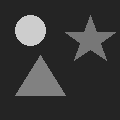

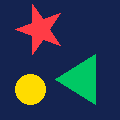

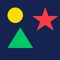

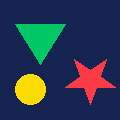

In [8]:
from PIL import Image
gris = imagen.convert("L")
print("Tamaño en escala de grises:", gris.size)
gris.save("mi_imagen_gris.png")

rotada = imagen.rotate(90, expand=True)
print("Tamaño de la imagen rotada:", rotada.size)
rotada.save("mi_imagen_rotada.png")

mitad = imagen.resize((60, 60))
print("Tamaño de la imagen reducida:", mitad.size)
mitad.save("mi_imagen_mitad.png")

volteada = imagen.transpose(Image.Transpose.FLIP_TOP_BOTTOM)
print("Tamaño de la imagen volteada:", volteada.size)
volteada.save("mi_imagen_volteada.png")

display(gris, rotada, mitad, volteada)

Píxel antes del brillo: (255, 60, 70)
Píxel después del brillo: (255, 150, 175)
Hay al menos un canal recortado en 255 o 0.


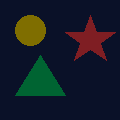

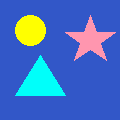

In [13]:
from PIL import ImageEnhance, ImageFilter
imagen = Image.open("mi_imagen.png")

brillo_bajo = ImageEnhance.Brightness(imagen).enhance(0.5)
brillo_bajo.save("mi_imagen_brillo_bajo.png")

brillo_alto = ImageEnhance.Brightness(imagen).enhance(2.5)
brillo_alto.save("mi_imagen_brillo_alto.png")

coordenada = (90, 35)

pixel_antes = imagen.getpixel(coordenada)
pixel_despues = brillo_alto.getpixel(coordenada)

print("Píxel antes del brillo:", pixel_antes)
print("Píxel después del brillo:", pixel_despues)

if any(canal == 255 or canal == 0 for canal in pixel_despues):
    print("Hay al menos un canal recortado en 255 o 0.")
else:
    print("Ningún canal del píxel está recortado en 255 o 0.")

display(brillo_bajo, brillo_alto)

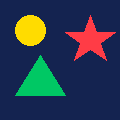

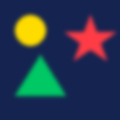

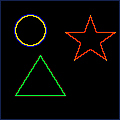

Se guardaron los dos filtros correctamente.


In [14]:
from PIL import ImageFilter

imagen_blur = imagen.filter(ImageFilter.GaussianBlur(radius=2))
imagen_blur.save("mi_imagen_blur.png")

imagen_bordes = imagen.filter(ImageFilter.FIND_EDGES)
imagen_bordes.save("mi_imagen_bordes.png")

display(imagen)
display(imagen_blur)
display(imagen_bordes)

print("Se guardaron los dos filtros correctamente.")

Pillow (.convert('L')): 36
scikit-image (rgb2gray): 35.06
Diferencia: 0.94


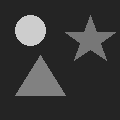

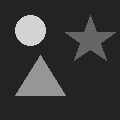

In [15]:
import numpy as np
from skimage import color, filters
array_rgb = np.array(imagen)

gris_skimage = color.rgb2gray(array_rgb)

gris_pillow = imagen.convert("L")

x, y = 5, 5

valor_pillow = gris_pillow.getpixel((x, y))
valor_skimage = gris_skimage[y, x] * 255

print("Pillow (.convert('L')):", valor_pillow)
print("scikit-image (rgb2gray):", round(valor_skimage, 2))
print("Diferencia:", round(abs(valor_pillow - valor_skimage), 2))

display(gris_pillow)
display(Image.fromarray((gris_skimage * 255).astype(np.uint8)))

Umbral de Otsu: 0.1388
Proporción de píxeles True: 0.1833
Porcentaje de píxeles True: 18.33 %


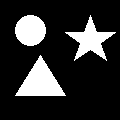

In [12]:
# Calcular automáticamente el umbral de Otsu
umbral = filters.threshold_otsu(gris_skimage)

# Binarizar la imagen
imagen_binaria = gris_skimage > umbral

# Calcular la proporción de píxeles True
proporcion_true = np.mean(imagen_binaria)

print("Umbral de Otsu:", round(umbral, 4))
print("Proporción de píxeles True:", round(proporcion_true, 4))
print("Porcentaje de píxeles True:", round(proporcion_true * 100, 2), "%")

# Guardar la imagen binaria
imagen_otsu = Image.fromarray(
    (imagen_binaria * 255).astype(np.uint8)
)
imagen_otsu.save("mi_imagen_otsu.png")

display(imagen_otsu)